y at t = tau: simulated 1.2650, theory 1.2640


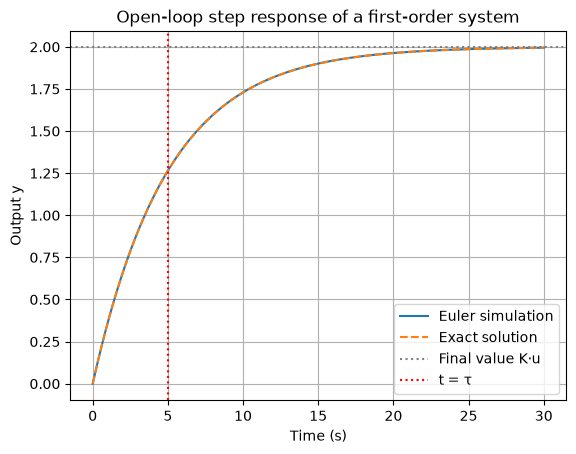

In [1]:
import numpy as np
import matplotlib.pyplot as plt

K = 2.0 # process gain
tau = 5.0 

dt = 0.01 #must be much smaller than tau
T_end = 30.0

t = np.arange(0, T_end, dt) 

def simulate_open_loop(u_value):
#simulate tau*dy/dt = -y + K*u."
    y = np.zeros_like(t) # start at y = 0
    for k in range(len(t) - 1):
        dydt = (-y[k] + K * u_value) / tau # the physics
        y[k + 1] = y[k] + dydt * dt # Euler step
    return y

u = 1.0
y_sim = simulate_open_loop(u)
y_exact = K * u * (1 - np.exp(-t / tau)) # analytical solution
idx = int(tau / dt) # index where t = tau
print(f"y at t = tau: simulated {y_sim[idx]:.4f}, theory {0.632 * K * u:.4f}")
plt.plot(t, y_sim, label="Euler simulation")
plt.plot(t, y_exact, "--", label="Exact solution")

plt.axhline(K * u, color="gray", linestyle=":", label="Final value K·u")
plt.axvline(tau, color="red", linestyle=":", label="t = τ")
plt.xlabel("Time (s)"); plt.ylabel("Output y")
plt.title("Open-loop step response of a first-order system")
plt.legend(); plt.grid(True); plt.show()


notice how the system settles at 5tau. you compare against the exact formula. the two curves should overlap almost perfectly, which confirms
the sim